<a href="https://colab.research.google.com/github/themdanas/Deep_Generative_Models/blob/main/diffusers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install -qq -U diffusers datasets transformers accelerate ftfy

In [ ]:
%pip install pyarrow==9.0.0

  Using cached pyarrow-9.0.0.tar.gz (873 kB)
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


In [30]:
from huggingface_hub import notebook_login

In [51]:
notebook_login()

In [3]:
#to store model checkpoints
%%capture
!sudo apt -qq install git-lfs
!git config --global credential.helper store

In [4]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

def show_images(x):
  #converting a batch of image to make a grid and convert to PIL
  grid = torchvision.utils.make_grid(x)
  grid_im = grid.detach().cpu().permute(1, 2, 0).clip(0, 1) * 255
  grid_im = Image.fromarray(np.array(grid_im).astype(np.uint8))

  return grid_im


def make_grid(images, size=64):
  #given the list of PIl images stack them together into a line
  output_im = Image.new("RGB", (size * len(images), size))
  for i, im in enumerate(images):
    output_im.paste(im.resize((size, size)), (i * size, 0))
  return output_im

device = "cuda" if torch.cuda.is_available() else "cpu"


In [5]:
#down loading the training dataset

import torchvision
#!pip uninstall -y datasets pyarrow
#!pip install datasets

from datasets import load_dataset
from torchvision import transforms

dataset = load_dataset("huggan/smithsonian_butterflies_subset", split="train")

image_size=32
batch_size=32

preprocess = transforms.Compose(
    [
        transforms.Resize((image_size, image_size)),
        transforms.RandomHorizontalFlip(), # randomly flip the image horizontally
        transforms.ToTensor(),
        transforms.Normalize([0.5, 0.5, 0.5],[0.5, 0.5, 0.5]),
    ]
)

def transform(examples):
  images =  [preprocess(image.convert("RGB")) for image in examples["image"]]
  return {"images": images}

dataset.set_transform(transform)

train_dataloader = torch.utils.data.DataLoader(
    dataset, batch_size=batch_size, shuffle=True
)

README.md:   0%|          | 0.00/609 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


dataset_infos.json:   0%|          | 0.00/1.65k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/237M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

X shape: torch.Size([8, 3, 32, 32])


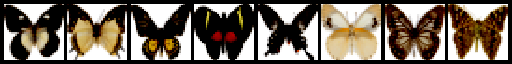

In [6]:
xb = next(iter(train_dataloader))["images"].to(device)[:8]
print("X shape:", xb.shape)
show_images(xb).resize((8 * 64, 64), resample=Image.NEAREST)

In [21]:
#dening the sechduler
from diffusers import DDPMScheduler

noise_scheduler = DDPMScheduler(num_train_timesteps=100)

The DDPM paper describes a corruption process that adds a small amount of noise for every 'timestep'. Given $x_{t-1}$ for some timestep, we can get the next (slightly more noisy) version $x_t$ with:<br><br>

$q(\mathbf{x}_t \vert \mathbf{x}_{t-1}) = \mathbf{N}(\mathbf{x}_t; \sqrt{1 - \beta_t} \mathbf{x}_{t-1}, \beta_t\mathbf{I}) \quad
q(\mathbf{x}_{1:T} \vert \mathbf{x}_0) = \prod^T_{t=1} q(\mathbf{x}_t \vert \mathbf{x}_{t-1})$<br><br>


That is, we take $x_{t-1}$, scale it by $\sqrt{1 - \beta_t}$ and add noise scaled by $\beta_t$. This $\beta$ is defined for every t according to some schedule, and determines how much noise is added per timestep. Now, we don't necessarily want to do this operation 500 times to get $x_{500}$ so we have another formula to get $x_t$ for any t given $x_0$: <br><br>

$\begin{aligned}
q(\mathbf{x}_t \vert \mathbf{x}_0) &= \mathbf{N}(\mathbf{x}_t; \sqrt{\bar{\alpha}_t} \mathbf{x}_0, {(1 - \bar{\alpha}_t)} \mathbf{I})
\end{aligned}$ where $\bar{\alpha}_t = \prod_{i=1}^T \alpha_i$ and $\alpha_i = 1-\beta_i$<br><br>

The maths notation always looks scary! Luckily the scheduler handles all that for us. We can plot $\sqrt{\bar{\alpha}_t}$ (labelled as `sqrt_alpha_prod`) and $\sqrt{(1 - \bar{\alpha}_t)}$ (labelled as `sqrt_one_minus_alpha_prod`) to view how the input (x) and the noise are scaled and mixed across different timesteps:

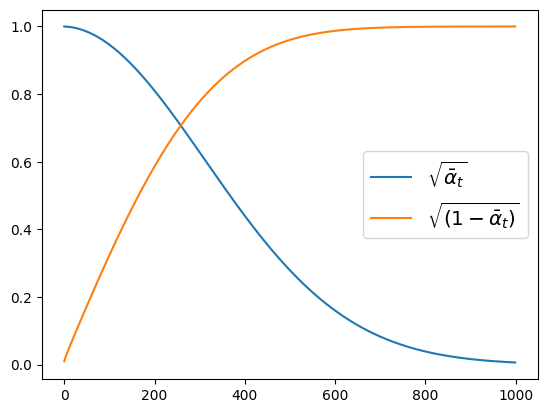

In [8]:
plt.plot(noise_scheduler.alphas_cumprod.cpu() ** 0.5, label=r"${\sqrt{\bar{\alpha}_t}}$")
plt.plot((1 - noise_scheduler.alphas_cumprod.cpu()) ** 0.5, label=r"$\sqrt{(1 - \bar{\alpha}_t)}$")
plt.legend(fontsize="x-large");

Noise X shape: torch.Size([8, 3, 32, 32])


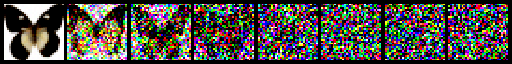

In [9]:
timesteps = torch.linspace(0, 999, 8).long().to(device)
noise = torch.randn_like(xb)
noise_xb = noise_scheduler.add_noise(xb, noise, timesteps)
print("Noise X shape:", noise_xb.shape)
show_images(noise_xb).resize((8 * 64, 64), resample=Image.NEAREST)

In [10]:
noise

tensor([[[[-1.3109e-01,  5.6037e-01, -1.9443e+00,  ..., -1.2812e+00,
           -9.1867e-01, -3.8987e-01],
          [ 3.4574e-02,  1.1548e-01,  2.9947e-01,  ..., -1.5914e-03,
           -1.0292e+00,  2.5275e-01],
          [ 1.5476e+00, -1.0343e+00,  1.3389e+00,  ...,  1.0116e+00,
            7.9239e-01,  2.3687e-01],
          ...,
          [-3.2693e-01, -1.3137e+00, -2.5248e-01,  ..., -1.3514e+00,
           -6.0572e-01,  8.7121e-01],
          [-2.1410e-01, -7.5763e-01,  1.5448e+00,  ..., -5.5167e-01,
            5.1337e-01,  8.7746e-01],
          [ 6.7551e-01,  6.4277e-01,  7.0195e-01,  ..., -8.0350e-01,
           -7.3871e-01,  7.9857e-01]],

         [[ 5.7465e-01,  9.7559e-02,  1.5672e+00,  ...,  3.8513e-01,
            8.4945e-01,  2.0788e-01],
          [-9.9610e-01, -1.0179e+00,  8.4869e-01,  ...,  3.5088e-01,
            2.0785e+00, -4.5616e-01],
          [ 7.7071e-01, -1.4098e+00, -3.8827e-01,  ...,  5.7818e-02,
           -1.7585e+00,  2.1672e-01],
          ...,
     

In [11]:
noise.shape

torch.Size([8, 3, 32, 32])

In [12]:
#defining the model
from diffusers import UNet2DModel

#creating the model
model = UNet2DModel(
    sample_size=image_size,
    in_channels=3,
    out_channels=3,
    layers_per_block=2,
    block_out_channels=(64,128,128,256),

    down_block_types=(
        "DownBlock2D",  # a regular ResNet downsampling block
        "DownBlock2D",
        "AttnDownBlock2D",  # a ResNet downsampling block with spatial self-attention
        "AttnDownBlock2D",
    ),
    up_block_types=(
        "AttnUpBlock2D",
        "AttnUpBlock2D",  # a ResNet upsampling block with spatial self-attention
        "UpBlock2D",
        "UpBlock2D",  # a regular ResNet upsampling block
    ),
  )

model.to(device)

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


UNet2DModel(
  (conv_in): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (time_proj): Timesteps()
  (time_embedding): TimestepEmbedding(
    (linear_1): Linear(in_features=64, out_features=256, bias=True)
    (act): SiLU()
    (linear_2): Linear(in_features=256, out_features=256, bias=True)
  )
  (down_blocks): ModuleList(
    (0): DownBlock2D(
      (resnets): ModuleList(
        (0-1): 2 x ResnetBlock2D(
          (norm1): GroupNorm(32, 64, eps=1e-05, affine=True)
          (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (time_emb_proj): Linear(in_features=256, out_features=64, bias=True)
          (norm2): GroupNorm(32, 64, eps=1e-05, affine=True)
          (dropout): Dropout(p=0.0, inplace=False)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (nonlinearity): SiLU()
        )
      )
      (downsamplers): ModuleList(
        (0): Downsample2D(
          (conv): Conv2d(64, 64, ker

In [13]:
with torch.no_grad():
    model_prediction = model(noise_xb, timesteps).sample
model_prediction.shape

torch.Size([8, 3, 32, 32])

In [14]:
noise_scheduler=DDPMScheduler(
    num_train_timesteps=100,
    beta_schedule="squaredcos_cap_v2"
)

#training loop
optimizer = torch.optim.AdamW(model.parameters(),lr=4e-4)

losses = []

for epoch in range(30):
  for steps, batch in enumerate(train_dataloader):
    clean_images = batch["images"].to(device)

    #sample noise to add images
    noise = torch.randn(clean_images.shape).to(clean_images.device)
    bs = clean_images.shape[0]

    #sample a random time stemps for each image
    timesteps = torch.randint(
        0, noise_scheduler.num_train_timesteps, (bs,), device=clean_images.device
    ).long()

    #adding noise to clean images accourding to the noise magnitude at each time stemps
    noisy_images = noise_scheduler.add_noise(clean_images, noise, timesteps)

    #getting the model predictions
    noise_pred = model(noisy_images, timesteps, return_dict=False)[0]

    #calculating the loss
    loss = F.mse_loss(noise_pred,noise)
    loss.backward()
    losses.append(loss.item())

    optimizer.step()
    optimizer.zero_grad()

  if(epoch +1) % 5 ==0:
    loss_last_epoch = sum(losses[-len(train_dataloader) :]) / len(train_dataloader)
    print(f"Epoch:{epoch+1}, loss: {loss_last_epoch}")



/usr/local/lib/python3.12/dist-packages/diffusers/configuration_utils.py:173: FutureWarning: Accessing config attribute `num_train_timesteps` directly via 'DDPMScheduler' object attribute is deprecated. Please access 'num_train_timesteps' over 'DDPMScheduler's config object instead, e.g. 'scheduler.config.num_train_timesteps'.
  deprecate("direct config name access", "1.0.0", deprecation_message, standard_warn=False)


Epoch:5, loss: 0.09113382967188954
Epoch:10, loss: 0.06940480228513479
Epoch:15, loss: 0.059042416396550834
Epoch:20, loss: 0.05576643079984933
Epoch:25, loss: 0.04810419550631195
Epoch:30, loss: 0.048287440673448145


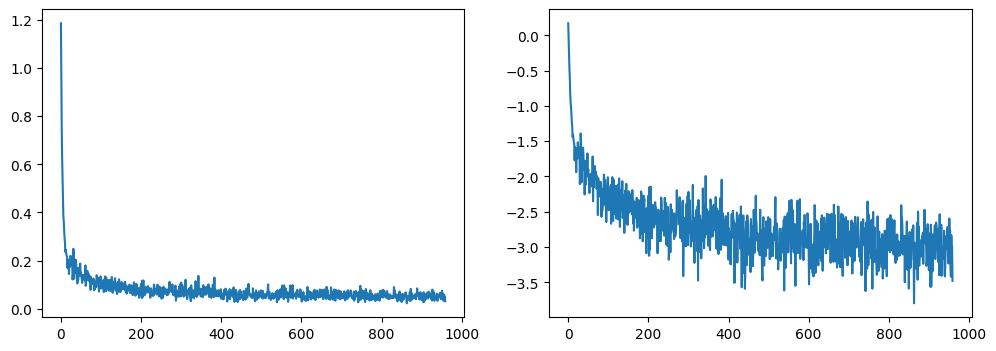

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(losses)
axs[1].plot(np.log(losses))
plt.show()

In [18]:
#generating the image
from diffusers import DDPMPipeline
image_pipe= DDPMPipeline(unet=model, scheduler=noise_scheduler)



  0%|          | 0/100 [00:00<?, ?it/s]

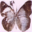

In [22]:
pipeline_output = image_pipe(num_inference_steps=100)
pipeline_output.images[0]

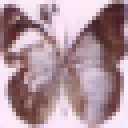

In [23]:
img = pipeline_output.images[0]

# Resize for display (e.g., to 256x256)
large_img = img.resize((128, 128), resample=Image.NEAREST)

from IPython.display import display

display(large_img)

In [24]:
image_pipe.save_pretrained("my_pipeline")

In [25]:
!ls my_pipeline/

model_index.json  scheduler  unet


In [53]:
from huggingface_hub import get_full_repo_name

model_name = "sd-class-butterflies-32-copy-1"
hub_model_id = get_full_repo_name(model_name)
hub_model_id

HfHubHTTPError: Invalid user token. The token from Google Colab vault is invalid. Please update it from the UI.